In [1]:
import numpy as np
import sacc
from lstomo import LargeScaleTomographer
from functools import partial
import pyccl as ccl
import matplotlib.pyplot as plt

# Read sacc file

In [ ]:
s = sacc.Sacc.load_fits("../cls_BGS_LRG_Quaia_KappaPR4_DESY3.fits")

In [3]:
def get_tracer_function(map_name):
    if map_name == 'KappaPR4':
        return partial(ccl.CMBLensingTracer, z_source=1100.)
    elif "DESY3" in map_name:
        return partial(ccl.WeakLensingTracer, dndz=(s.tracers[map_name].z, s.tracers[map_name].nz))
    else:
        raise ValueError(f"Unknown map name: {map_name}")

# Let's create two lensing tomographers. One will only use CMB lensing, while the other one
# will also take advantage of cosmic shear.
tomo1 = LargeScaleTomographer(s,
                      gal_names=['DESI_BGS__0', 'DESI_BGS__1',
                                 'DESI_LRG__0', 'DESI_LRG__1', 'DESI_LRG__2', 'DESI_LRG__3',
                                 'Quaia__1', 'Quaia__2'],
                      map_names=['KappaPR4'],
                      comp_names=['matter'],
                      tracer_classes={'matter': 
                                      {m: get_tracer_function(m)
                                       for m in ['KappaPR4']}},
                      maps_in_x='all', n_max=1, kmax=0.3)
tomo2 = LargeScaleTomographer(s,
                      gal_names=['DESI_BGS__0', 'DESI_BGS__1',
                                 'DESI_LRG__0', 'DESI_LRG__1', 'DESI_LRG__2', 'DESI_LRG__3',
                                 'Quaia__1', 'Quaia__2'],
                      map_names=['KappaPR4', 'DESY3wl__0', 'DESY3wl__1',
                                 'DESY3wl__2', 'DESY3wl__3'],
                      comp_names=['matter'],
                      tracer_classes={'matter': 
                                      {m: get_tracer_function(m)
                                       for m in ['KappaPR4', 'DESY3wl__0',
                                                 'DESY3wl__1', 'DESY3wl__2',
                                                 'DESY3wl__3']}},
                      maps_in_x={'DESI_BGS__0': ['KappaPR4', 'DESY3wl__0', 'DESY3wl__1', 'DESY3wl__2', 'DESY3wl__3'],
                                 'DESI_BGS__1': ['KappaPR4', 'DESY3wl__0', 'DESY3wl__1', 'DESY3wl__2', 'DESY3wl__3'],
                                 'DESI_LRG__0': ['KappaPR4', 'DESY3wl__1', 'DESY3wl__2', 'DESY3wl__3'],
                                 'DESI_LRG__1': ['KappaPR4', 'DESY3wl__2', 'DESY3wl__3'],
                                 'DESI_LRG__2': ['KappaPR4', 'DESY3wl__3'],
                                 'DESI_LRG__3': ['KappaPR4', 'DESY3wl__3'],
                                 'Quaia__1': ['KappaPR4'],
                                 'Quaia__2': ['KappaPR4']},
                      map_spin={'KappaPR4': 0,
                                'DESY3wl__0': 2,
                                'DESY3wl__1': 2,
                                'DESY3wl__2': 2,
                                'DESY3wl__3': 2}, n_max=1, kmax=0.3)

/home/david/miniforge3/envs/analysis/lib/python3.14/site-packages/sacc/sacc.py:436: UserWarning: Empty index selected - maybe you should check the tracer order?
  warnings.warn("Empty index selected - maybe you "


# Get tomographic biases
(running quick MCMC likelihood)

In [4]:
bgs1, bUs1, _, _ = tomo1.get_linear_biases(nsteps=10000, burnin=2000)
bgs2, bUs2, _, _ = tomo2.get_linear_biases(nsteps=10000, burnin=2000)

# Plot results

(0.1, 3.0)

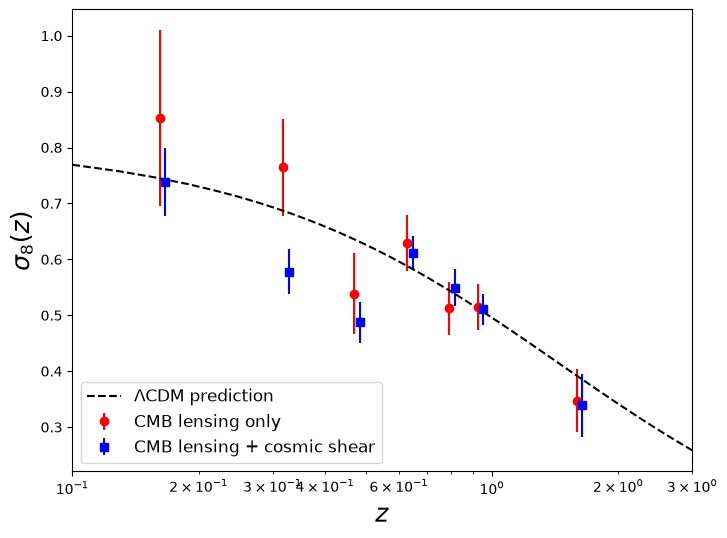

In [5]:
zs = np.array([tomo1.tracer_data[gal_name]['z_mean'] for gal_name in tomo1.gal_names])
s80 = (ccl.growth_factor(tomo1.cosmo, 1/(1+zs))*tomo1.cosmo['sigma8'])[:-1]

plt.figure(figsize=(8, 6))
plt.errorbar(zs[:-1],
             s80*np.array([bUs1[(gal_name, 'matter')][0] for gal_name in tomo1.gal_names])[:-1],
             yerr=s80*np.array([bUs1[(gal_name, 'matter')][1] for gal_name in tomo1.gal_names])[:-1],
             fmt='ro', label='CMB lensing only')

plt.errorbar(1.03*zs[:-1],
             s80*np.array([bUs2[(gal_name, 'matter')][0] for gal_name in tomo2.gal_names])[:-1],
             yerr=s80*np.array([bUs2[(gal_name, 'matter')][1] for gal_name in tomo2.gal_names])[:-1],
             fmt='bs', label='CMB lensing + cosmic shear')

zz = np.linspace(0.1, 3.0, 100)
s8z = ccl.growth_factor(tomo1.cosmo, 1/(1+zz))*tomo1.cosmo['sigma8']
plt.plot(zz, s8z, 'k--', label=r'$\Lambda$CDM prediction')
plt.xscale('log')
plt.xlabel(r'$z$', fontsize=18)
plt.ylabel(r'$\sigma_8(z)$', fontsize=18)
plt.legend(fontsize=12, loc='lower left')
plt.xlim([0.1, 3.0])
